# What changed: keeping up with IdroGEO

IdroGEO is a living database: regions and ISPRA add and validate
landslides and events every day. This notebook shows how to follow those
changes without downloading the inventory again.

In [1]:
# pip install "ispra-idrogeo[geo]" matplotlib
from ispra_idrogeo import IdroGEO

idrogeo = IdroGEO()  # one client for the whole notebook; no account, no key

## Dated landslide events, year by year

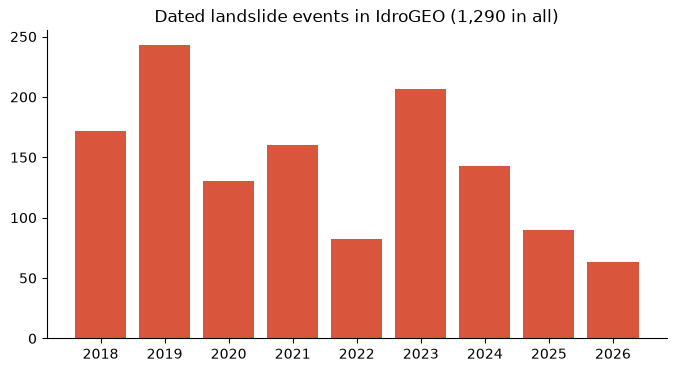

In [2]:
import matplotlib.pyplot as plt

italy = await idrogeo.summary("iffi", "italia")
years = sorted(italy["eventi_stats"], key=lambda s: s["anno"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([str(s["anno"]) for s in years], [s["nr_eventi"] for s in years], color="#d9553b")
ax.set_title(f"Dated landslide events in IdroGEO ({italy['eventi_totali']:,} in all)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## What changed in the last days

`modified_since` asks only for the records changed since a time. With
`select=["*"]` they come with their geometry, ready to update a local copy.

In [3]:
from datetime import UTC, datetime, timedelta

since = datetime.now(UTC) - timedelta(days=7)
landslides = [
    f
    async for f in idrogeo.iter_landslides(
        modified_since=since, select=["id_frana", "modified", "tipo_movimento", "regione"]
    )
]
events = [
    e
    async for e in idrogeo.iter_events(
        modified_since=since, select=["uid", "modified", "computed_date", "comune_nome"]
    )
]
print(f"in the last 7 days: {len(landslides)} landslides and {len(events)} events changed")
events[:3]

in the last 7 days: 57 landslides and 4 events changed


[{'uid': 'EIT202500029',
  'modified': '2026-10-30T11:44:14.677+00:00',
  'computed_date': '2025-03-22T00:00',
  'comune_nome': 'Val Masino'},
 {'uid': 'EIT202600090',
  'modified': '2026-11-03T16:46:16.064+00:00',
  'computed_date': '2026-09-01T14:30',
  'comune_nome': 'Olmo al Brembo'},
 {'uid': 'EIT202600096',
  'modified': '2026-11-03T16:42:21.178+00:00',
  'computed_date': '2026-09-10T00:00',
  'comune_nome': 'Val Masino'}]

## One round of `idrogeo watch`

`changes` returns what changed since a mark, and the next mark: run it
again and nothing comes back twice. `idrogeo watch --once` does this from
cron, saving the marks to a file.

In [4]:
from ispra_idrogeo.watch import Mark, changes

rows, mark = await changes(idrogeo, "events", Mark(since))
again, _ = await changes(idrogeo, "events", mark)
print(len(rows), "changed events, then", len(again), "on the next round")

4 changed events, then 0 on the next round


In [5]:
await idrogeo.aclose()

Source: ISPRA — IdroGEO (CC BY 4.0).